# ToysGroup – Esercitazione finale Python for Data Science

## Task 2 – Lettura e ispezione dei dati

Obiettivo: importare i quattro dataset, esaminarne struttura e contenuto e svolgere le operazioni richieste con Pandas e NumPy, senza modificare i DataFrame originali.

In [174]:

import pandas as pd
import numpy as np

# Lettura dei quattro file
products = pd.read_csv("products.csv")
regions = pd.read_excel("regions.xlsx")
sales = pd.read_json("sales.json")
resellers = pd.read_csv("resellers.csv")

# Ispezione dei DataFrame
datasets = {
    "PRODOTTI": products,
    "REGIONI": regions,
    "VENDITE": sales,
    "RIVENDITORI": resellers
}

for nome, df in datasets.items():
    print(f"\n===== {nome} =====")
    print("Dimensioni (righe, colonne):", df.shape)

    print("\nInformazioni generali:")
    df.info()

    print("\nPrime 5 righe:")
    display(df.head())

    print("\nUltime 5 righe:")
    display(df.tail())



===== PRODOTTI =====
Dimensioni (righe, colonne): (12, 4)

Informazioni generali:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   ProductID    12 non-null     int64  
 1   ProductName  12 non-null     object 
 2   Category     12 non-null     object 
 3   ListPrice    12 non-null     float64
dtypes: float64(1), int64(1), object(2)
memory usage: 516.0+ bytes

Prime 5 righe:


,ProductID,ProductName,Category,ListPrice
0,1,Bici Junior,Outdoor,129.0
1,2,Bici BMX,Outdoor,189.0
2,3,Monopattino,Outdoor,79.0
3,4,Pallone Calcio,Outdoor,19.9
4,5,Racchette Beach,Outdoor,14.5



Ultime 5 righe:


,ProductID,ProductName,Category,ListPrice
7,8,Scacchi Legno,Giochi da tavolo,34.0
8,9,Costruzioni 500,Giocattoli,39.9
9,10,Bambola Classica,Giocattoli,24.9
10,11,Robot RC,Giocattoli,89.0
11,12,Macchinina RC,Giocattoli,59.0



===== REGIONI =====
Dimensioni (righe, colonne): (9, 3)

Informazioni generali:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   RegionID     9 non-null      int64 
 1   State        9 non-null      object
 2   SalesRegion  9 non-null      object
dtypes: int64(1), object(2)
memory usage: 348.0+ bytes

Prime 5 righe:


,RegionID,State,SalesRegion
0,1,Italia,Sud Europa
1,2,Francia,Sud Europa
2,3,Spagna,Sud Europa
3,4,Germania,Centro Europa
4,5,Austria,Centro Europa


... (6 outputs left out)


===== RIVENDITORI =====
Dimensioni (righe, colonne): (300, 7)

Informazioni generali:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   ResellerID          300 non-null    int64  
 1   RegionID            300 non-null    int64  
 2   Ordini12m           300 non-null    int64  
 3   GiorniUltimoOrdine  300 non-null    int64  
 4   ScontoMedio         300 non-null    float64
 5   Reclami             300 non-null    int64  
 6   Churn               300 non-null    int64  
dtypes: float64(1), int64(6)
memory usage: 16.5 KB

Prime 5 righe:


,ResellerID,RegionID,Ordini12m,GiorniUltimoOrdine,ScontoMedio,Reclami,Churn
0,1,1,14,65,0.131,1,0
1,2,7,9,149,0.117,1,0
2,3,6,21,1,0.065,2,0
3,4,4,18,162,0.011,1,1
4,5,4,22,98,0.120,0,0



Ultime 5 righe:


,ResellerID,RegionID,Ordini12m,GiorniUltimoOrdine,ScontoMedio,Reclami,Churn
295,296,5,18,145,0.218,1,0
296,297,8,17,104,0.048,0,0
297,298,4,16,141,0.055,2,0
298,299,3,13,113,0.164,0,0
299,300,1,12,116,0.072,0,0


In [175]:

# Statistiche descrittive
display(sales[["Quantity", "SalesAmount"]].describe())

# Conversione delle colonne in array NumPy
quantita = sales["Quantity"].to_numpy(dtype=float)
fatturato = sales["SalesAmount"].to_numpy(dtype=float)

# Calcolo vettoriale del prezzo unitario
prezzo_unitario = np.divide(
    fatturato,
    quantita,
    out=np.full_like(fatturato, np.nan),
    where=(quantita != 0) & ~np.isnan(quantita)
)

print("Primi 10 prezzi unitari:")
print(prezzo_unitario[:10])
 

,Quantity,SalesAmount
count,1900.000000,1900.000000
mean,4.966316,294.776579
std,2.206535,305.261212
min,1.000000,12.500000
25%,3.000000,89.000000
50%,5.000000,177.000000
75%,6.000000,387.000000
max,14.000000,2457.000000


Primi 10 prezzi unitari:
[17.9  nan 59.   nan  nan 12.5 79.  79.  12.5  nan]


In [176]:

# Selezione dei prodotti Bikes con prezzo superiore a 30 €
prodotti_filtrati = products.loc[
    (products["Category"] == "Bikes") &
    (products["ListPrice"] > 30)
]

display(prodotti_filtrati)

# Selezione delle righe 10-19 e prime 3 colonne
selezione_sales = sales.iloc[10:20, :3]

display(selezione_sales)
print("Dimensioni:", selezione_sales.shape)
 

,ProductID,ProductName,Category,ListPrice


,SalesID,ProductID,RegionID
10,218,1,8
11,1136,1,9
12,1326,3,4
13,1063,9,7
14,1606,10,8
15,1283,12,1
16,98,3,4
17,156,6,8
18,1642,12,5
19,1644,4,7


Dimensioni: (10, 3)


In [177]:

# Statistiche descrittive di Quantity e SalesAmount
display(sales[["Quantity", "SalesAmount"]].describe())

# Conversione delle colonne in array NumPy
quantita = sales["Quantity"].to_numpy(dtype=float)
fatturato = sales["SalesAmount"].to_numpy(dtype=float)

# Calcolo vettoriale del prezzo unitario
prezzo_unitario = np.divide(
    fatturato,
    quantita,
    out=np.full_like(fatturato, np.nan),
    where=(quantita != 0) & ~np.isnan(quantita)
)

print("Primi 10 prezzi unitari:")
print(prezzo_unitario[:10])


,Quantity,SalesAmount
count,1900.000000,1900.000000
mean,4.966316,294.776579
std,2.206535,305.261212
min,1.000000,12.500000
25%,3.000000,89.000000
50%,5.000000,177.000000
75%,6.000000,387.000000
max,14.000000,2457.000000


Primi 10 prezzi unitari:
[17.9  nan 59.   nan  nan 12.5 79.  79.  12.5  nan]


In [178]:

# Prodotti Bikes con prezzo superiore a 30 €
prodotti_filtrati = products.loc[
    (products["Category"] == "Bikes") &
    (products["ListPrice"] > 30)
]

print("Prodotti selezionati:")
display(prodotti_filtrati)

# Righe dalla posizione 10 alla 19 e prime 3 colonne
selezione_sales = sales.iloc[10:20, :3]

display(selezione_sales)
print("Dimensioni:", selezione_sales.shape)


Prodotti selezionati:


,ProductID,ProductName,Category,ListPrice


,SalesID,ProductID,RegionID
10,218,1,8
11,1136,1,9
12,1326,3,4
13,1063,9,7
14,1606,10,8
15,1283,12,1
16,98,3,4
17,156,6,8
18,1642,12,5
19,1644,4,7


Dimensioni: (10, 3)


### Task 2 – Definizioni richieste

**Series e DataFrame:** una Series è una struttura dati monodimensionale di Pandas, mentre un DataFrame è una struttura bidimensionale organizzata in righe e colonne.

**loc e iloc:** `loc[]` permette di selezionare righe e colonne utilizzando etichette o condizioni booleane. `iloc[]` utilizza invece le posizioni numeriche. Negli intervalli di `iloc[]`, l'estremo finale è escluso.

## Task 3a – Dati mancanti, filtri e ordinamento

**Obiettivo:** individuare e trattare i valori mancanti nel dataset delle vendite, quindi selezionare e ordinare le transazioni con importi superiori al 90° percentile.

### 3a.1 – Analisi dei valori mancanti

In [179]:

# Numero di valori mancanti per colonna
nan_prima = sales.isna().sum()

# Percentuale di valori mancanti
percentuale_nan = sales.isna().mean() * 100

# Tabella riepilogativa
tabella_nan_prima = pd.DataFrame({
    "Valori mancanti": nan_prima,
    "Percentuale (%)": percentuale_nan.round(2)
})

display(tabella_nan_prima)


,Valori mancanti,Percentuale (%)
SalesID,0,0.0
ProductID,0,0.0
RegionID,0,0.0
ResellerID,0,0.0
SalesDate,0,0.0
Quantity,100,5.0
SalesAmount,100,5.0


In [180]:

# Creiamo una copia del dataset originale
sales_clean = sales.copy()

# Calcoliamo la mediana sui valori presenti
mediana_quantity = sales_clean["Quantity"].median()

# Sostituiamo i NaN di Quantity con la mediana
sales_clean["Quantity"] = sales_clean["Quantity"].fillna(
    mediana_quantity
)

# Numero di righe prima dell'eliminazione
righe_prima = len(sales_clean)

# Eliminiamo le righe con SalesAmount mancante
sales_clean = sales_clean.dropna(subset=["SalesAmount"])

# Calcoliamo quante righe sono state eliminate
righe_eliminate = righe_prima - len(sales_clean)

# Verifichiamo i risultati
print("Mediana Quantity:", mediana_quantity)
print("Righe eliminate:", righe_eliminate)
print("Righe rimanenti:", len(sales_clean))

print("\nValori mancanti dopo il trattamento:")
display(sales_clean.isna().sum())


Mediana Quantity: 5.0
Righe eliminate: 100
Righe rimanenti: 1900

Valori mancanti dopo il trattamento:


SalesID        0
ProductID      0
RegionID       0
ResellerID     0
SalesDate      0
Quantity       0
SalesAmount    0
dtype: int64

In [181]:

# Creiamo una copia delle vendite originali
sales_clean = sales.copy()

# Sostituiamo i valori mancanti di Quantity
mediana_quantity = sales_clean["Quantity"].median()

sales_clean["Quantity"] = sales_clean["Quantity"].fillna(
    mediana_quantity
)

# Eliminiamo le righe senza SalesAmount
righe_prima = len(sales_clean)

sales_clean = sales_clean.dropna(
    subset=["SalesAmount"]
)

righe_eliminate = righe_prima - len(sales_clean)

# Verifichiamo i risultati
print("Mediana Quantity:", mediana_quantity)
print("Righe eliminate:", righe_eliminate)
print("Righe rimanenti:", len(sales_clean))

print("\nValori mancanti dopo il trattamento:")
display(sales_clean.isna().sum())


Mediana Quantity: 5.0
Righe eliminate: 100
Righe rimanenti: 1900

Valori mancanti dopo il trattamento:


SalesID        0
ProductID      0
RegionID       0
ResellerID     0
SalesDate      0
Quantity       0
SalesAmount    0
dtype: int64

In [182]:

# Confronto dei valori mancanti
confronto_nan = pd.DataFrame({
    "NaN prima": sales.isna().sum(),
    "NaN dopo": sales_clean.isna().sum()
})

display(confronto_nan)


,NaN prima,NaN dopo
SalesID,0,0
ProductID,0,0
RegionID,0,0
ResellerID,0,0
SalesDate,0,0
Quantity,100,0
SalesAmount,100,0


In [183]:

# Calcoliamo il 90° percentile del fatturato
soglia_90 = sales_clean["SalesAmount"].quantile(0.9)

# Selezioniamo le vendite sopra la soglia
vendite_alte = sales_clean.query(
    "SalesAmount > @soglia_90"
)

# Ordiniamo per data crescente e importo decrescente
vendite_alte = vendite_alte.sort_values(
    by=["SalesDate", "SalesAmount"],
    ascending=[True, False]
)

print("90° percentile:", soglia_90)
print("Numero di vendite selezionate:", len(vendite_alte))

display(vendite_alte.head(10))


90° percentile: 756.0
Numero di vendite selezionate: 162


,SalesID,ProductID,RegionID,ResellerID,SalesDate,Quantity,SalesAmount
32,1045,2,4,82,2023-01-16,6.0,1134.0
49,1872,2,7,204,2023-01-25,5.0,945.0
52,1639,1,3,299,2023-01-27,9.0,1161.0
102,296,2,9,202,2023-02-25,5.0,945.0
118,1462,2,2,224,2023-03-03,5.0,945.0
121,1221,1,8,149,2023-03-05,8.0,1032.0
123,1753,2,8,151,2023-03-05,5.0,945.0
168,283,2,2,100,2023-03-30,11.0,2079.0
217,1679,1,4,22,2023-04-27,5.0,774.0
221,832,2,4,82,2023-04-28,6.0,1134.0


### Task 3a – Definizioni e interpretazione

**Imputazione dei dati mancanti:** è il procedimento con cui si sostituiscono i valori assenti con valori stimati, per conservare le osservazioni nel dataset.

**Media:** è indicata soprattutto quando i dati presentano una distribuzione relativamente simmetrica e senza valori estremi significativi. Può essere influenzata dagli outlier.

**Mediana:** è preferibile quando la distribuzione è asimmetrica o contiene valori estremi, perché è meno sensibile agli outlier.

**Eliminazione delle righe:** consiste nel rimuovere le osservazioni che presentano valori mancanti. È utile quando una variabile essenziale non è disponibile, ma può ridurre la quantità di informazioni e introdurre distorsioni.

**Effetto sulla distribuzione:** l'imputazione con la media o la mediana concentra i valori mancanti attorno al valore scelto, riducendo potenzialmente la variabilità osservata. L'eliminazione delle righe può invece alterare la distribuzione se i dati mancanti non sono casuali.

Nel caso ToysGroup, la colonna Quantity viene completata utilizzando la mediana, mentre le transazioni prive di SalesAmount vengono eliminate, come richiesto dalla consegna.

## Task 3b – Aggregazioni e combinazione dei DataFrame

### 3b.1 – Unione dei dataset

**Obiettivo:** combinare il dataset delle vendite pulito con le informazioni relative ai prodotti e alle regioni geografiche.

Viene utilizzato un `left merge` per mantenere tutte le transazioni del dataset delle vendite, anche quando non è disponibile una corrispondenza nelle tabelle anagrafiche.

In [184]:

# Unione delle vendite con i prodotti
sales_merged = pd.merge(
    sales_clean,
    products,
    on="ProductID",
    how="left"
)

# Unione con le regioni
sales_merged = pd.merge(
    sales_merged,
    regions,
    on="RegionID",
    how="left"
)

# Controllo del numero di righe
print("Righe vendite pulite:", len(sales_clean))
print("Righe dopo il merge:", len(sales_merged))

assert len(sales_clean) == len(sales_merged), \
    "Attenzione: il merge ha modificato il numero di righe!"

print("Merge completato correttamente!")

display(sales_merged.head())


Righe vendite pulite: 1900
Righe dopo il merge: 1900
Merge completato correttamente!


,SalesID,ProductID,RegionID,ResellerID,SalesDate,Quantity,SalesAmount,ProductName,Category,ListPrice,State,SalesRegion
0,1194,6,7,283,2023-01-01,4.0,71.6,Puzzle 1000,Giochi da tavolo,17.9,Svezia,Nord Europa
1,1747,12,3,281,2023-01-02,2.0,118.0,Macchinina RC,Giocattoli,59.0,Spagna,Sud Europa
2,947,7,8,166,2023-01-04,6.0,75.0,Gioco dell'Oca,Giochi da tavolo,12.5,Norvegia,Nord Europa
3,577,3,4,285,2023-01-04,3.0,237.0,Monopattino,Outdoor,79.0,Germania,Centro Europa
4,78,3,8,107,2023-01-04,3.0,237.0,Monopattino,Outdoor,79.0,Norvegia,Nord Europa


In [185]:

# Aggregazione per categoria
fatturato_categoria = sales_merged.groupby(
    "Category"
).agg(
    FatturatoTotale=("SalesAmount", "sum"),
    QuantitaTotale=("Quantity", "sum"),
    NumeroTransazioni=("SalesID", "count")
).sort_values(
    "FatturatoTotale",
    ascending=False
)

display(fatturato_categoria)

# Categoria con fatturato più alto
categoria_top = fatturato_categoria.index[0]
fatturato_top = fatturato_categoria.iloc[0]["FatturatoTotale"]

print("Categoria con fatturato massimo:", categoria_top)
print("Fatturato:", round(fatturato_top, 2), "€")


,FatturatoTotale,QuantitaTotale,NumeroTransazioni
Category,,,
Outdoor,331998.4,3800.0,767
Giocattoli,174832.0,3225.0,644
Giochi da tavolo,53245.1,2416.0,489


Categoria con fatturato massimo: Outdoor
Fatturato: 331998.4 €


In [186]:

# Aggregazione per regione
fatturato_regione = sales_merged.groupby(
    "SalesRegion"
).agg(
    FatturatoTotale=("SalesAmount", "sum"),
    QuantitaTotale=("Quantity", "sum"),
    NumeroTransazioni=("SalesID", "count")
).sort_values(
    "FatturatoTotale",
    ascending=False
)

display(fatturato_regione)


,FatturatoTotale,QuantitaTotale,NumeroTransazioni
SalesRegion,,,
Centro Europa,201062.2,3413.0,698
Nord Europa,190189.0,3175.0,633
Sud Europa,168824.3,2853.0,569


### 3b.4 – Suddivisione delle vendite per anno e ricombinazione con concat()

In [187]:

# Conversione della data in formato datetime
sales_merged["SalesDate"] = pd.to_datetime(
    sales_merged["SalesDate"]
)

# Vendite del 2025
sales_2025 = sales_merged[
    sales_merged["SalesDate"].dt.year == 2025
].copy()

# Vendite degli altri anni
sales_altri_anni = sales_merged[
    sales_merged["SalesDate"].dt.year != 2025
].copy()

# Ricombinazione dei DataFrame
sales_ricombinate = pd.concat(
    [sales_2025, sales_altri_anni],
    ignore_index=True
)

print("Vendite 2025:", len(sales_2025))
print("Vendite altri anni:", len(sales_altri_anni))
print("Totale ricombinato:", len(sales_ricombinate))
print("Totale originale:", len(sales_merged))

assert len(sales_ricombinate) == len(sales_merged)

print("Numero di righe verificato!")


Vendite 2025: 640
Vendite altri anni: 1260
Totale ricombinato: 1900
Totale originale: 1900
Numero di righe verificato!


### Task 3b – Definizioni

**merge():** permette di combinare due DataFrame utilizzando una o più colonne chiave comuni. In questa analisi viene utilizzato un left merge per conservare tutte le transazioni di vendita.

**join():** permette di combinare DataFrame principalmente attraverso gli indici, oppure utilizzando una colonna del DataFrame di sinistra.

**concat():** permette di concatenare più DataFrame lungo le righe o le colonne, senza effettuare un abbinamento relazionale sulle chiavi.

**Differenza principale:** merge e join collegano informazioni attraverso chiavi o indici, mentre concat accoda o affianca strutture dati.

### Risultato dell'analisi

La categoria che genera il fatturato più elevato è **[INSERIRE CATEGORIA]**, con un fatturato complessivo di **[INSERIRE IMPORTO] €**.

Il confronto tra il numero di righe prima e dopo le operazioni di merge e concat permette di verificare che nessuna transazione sia stata persa o duplicata.

## Task 3c – Analisi delle serie temporali

### 3c.1 – Preparazione dei dati temporali

**Obiettivo:** analizzare l'evoluzione mensile del fatturato ToysGroup, utilizzando le funzionalità datetime di Pandas.

In [188]:

# Creiamo una copia del dataset unito
sales_time = sales_merged.copy()

# Convertiamo SalesDate in datetime
sales_time["SalesDate"] = pd.to_datetime(
    sales_time["SalesDate"],
    errors="coerce"
)

# Verifichiamo il formato e l'intervallo delle date
print("Tipo di dato:", sales_time["SalesDate"].dtype)
print("Prima data:", sales_time["SalesDate"].min())
print("Ultima data:", sales_time["SalesDate"].max())

# Controlliamo eventuali date non valide
print("Date mancanti:", sales_time["SalesDate"].isna().sum())


Tipo di dato: datetime64[ns]
Prima data: 2023-01-01 00:00:00
Ultima data: 2025-12-30 00:00:00
Date mancanti: 0


### 3c.2 – Aggregazione mensile del fatturato

In [189]:

# Raggruppiamo il fatturato per mese
fatturato_mensile = (
    sales_time
    .dropna(subset=["SalesDate"])
    .set_index("SalesDate")
    .resample("MS")["SalesAmount"]
    .sum()
)

print("Fatturato mensile:")
display(fatturato_mensile.to_frame("FatturatoMensile"))


Fatturato mensile:


,FatturatoMensile
SalesDate,
2023-01-01,11499.8
2023-02-01,9414.9
2023-03-01,14917.2
2023-04-01,11077.9
2023-05-01,10806.7
2023-06-01,11637.3
2023-07-01,10161.0
2023-08-01,15387.5
2023-09-01,14361.2


### 3c.3 – Variazione percentuale del fatturato

In [190]:

# Calcoliamo la variazione percentuale mese su mese
variazione_mensile = fatturato_mensile.pct_change(
    fill_method=None
) * 100

# Creiamo una tabella riepilogativa
analisi_mensile = pd.DataFrame({
    "FatturatoMensile": fatturato_mensile,
    "VariazionePercentuale": variazione_mensile
})

display(analisi_mensile.round(2))


,FatturatoMensile,VariazionePercentuale
SalesDate,,
2023-01-01,11499.8,NaN
2023-02-01,9414.9,-18.13
2023-03-01,14917.2,58.44
2023-04-01,11077.9,-25.74
2023-05-01,10806.7,-2.45
2023-06-01,11637.3,7.69
2023-07-01,10161.0,-12.69
2023-08-01,15387.5,51.44
2023-09-01,14361.2,-6.67


### 3c.4 – Analisi del mese più recente

In [191]:

# Individuiamo il mese dell'ultima vendita
ultima_data = sales_time["SalesDate"].max()

if pd.isna(ultima_data):
    print("Non sono disponibili date valide.")
else:
    ultimo_mese = ultima_data.to_period("M")

    # Selezioniamo le vendite dell'ultimo mese
    vendite_ultimo_mese = sales_time.loc[
        sales_time["SalesDate"].dt.to_period("M") == ultimo_mese
    ]

    fatturato_ultimo_mese = vendite_ultimo_mese["SalesAmount"].sum()

    print("Mese più recente:", ultimo_mese)
    print("Numero transazioni:", len(vendite_ultimo_mese))
    print("Fatturato ultimo mese:", round(fatturato_ultimo_mese, 2))

    display(vendite_ultimo_mese.head(10))


Mese più recente: 2025-12
Numero transazioni: 50
Fatturato ultimo mese: 13776.6


,SalesID,ProductID,RegionID,ResellerID,SalesDate,Quantity,SalesAmount,ProductName,Category,ListPrice,State,SalesRegion
1850,641,5,6,129,2025-12-01,5.0,72.5,Racchette Beach,Outdoor,14.5,Svizzera,Centro Europa
1851,1236,8,1,147,2025-12-02,5.0,170.0,Scacchi Legno,Giochi da tavolo,34.0,Italia,Sud Europa
1852,1928,12,3,96,2025-12-04,4.0,236.0,Macchinina RC,Giocattoli,59.0,Spagna,Sud Europa
1853,1100,8,4,155,2025-12-05,8.0,272.0,Scacchi Legno,Giochi da tavolo,34.0,Germania,Centro Europa
1854,744,1,3,66,2025-12-05,4.0,516.0,Bici Junior,Outdoor,129.0,Spagna,Sud Europa
1855,13,4,1,56,2025-12-05,4.0,79.6,Pallone Calcio,Outdoor,19.9,Italia,Sud Europa
1856,1551,1,4,44,2025-12-05,5.0,645.0,Bici Junior,Outdoor,129.0,Germania,Centro Europa
1857,7,2,7,283,2025-12-05,7.0,1323.0,Bici BMX,Outdoor,189.0,Svezia,Nord Europa
1858,95,7,5,21,2025-12-06,5.0,62.5,Gioco dell'Oca,Giochi da tavolo,12.5,Austria,Centro Europa
1859,364,5,5,186,2025-12-06,5.0,72.5,Racchette Beach,Outdoor,14.5,Austria,Centro Europa


In [192]:

# Escludiamo i valori non validi
variazioni_valide = variazione_mensile.replace(
    [np.inf, -np.inf], np.nan
).dropna()

if variazioni_valide.empty:
    print("Non ci sono variazioni mensili valide.")
else:
    mese_crescita_massima = variazioni_valide.idxmax()
    crescita_massima = variazioni_valide.max()

    print(
        "Mese con crescita maggiore:",
        mese_crescita_massima.strftime("%Y-%m")
    )
    print(
        "Crescita percentuale:",
        round(crescita_massima, 2),
        "%"
    )


Mese con crescita maggiore: 2024-03
Crescita percentuale: 110.84 %


### Task 3c – Interpretazione e definizioni

**Datetime:** è un tipo di dato che permette di rappresentare e manipolare date e orari. In Pandas consente di estrarre informazioni come anno, mese e giorno e di effettuare analisi temporali.

**Resample:** permette di raggruppare i dati secondo una frequenza temporale, ad esempio giornaliera, mensile o annuale.

**pct_change():** calcola la variazione relativa tra un valore e quello precedente. Moltiplicando il risultato per 100 si ottiene la variazione percentuale.

### Interpretazione dei risultati

L'analisi mensile permette di osservare come varia il fatturato di ToysGroup nel tempo e di identificare eventuali periodi di crescita o contrazione.

Il mese più recente presente nel dataset è **[INSERIRE MESE]**, con un fatturato di **[INSERIRE IMPORTO]**.

Il mese che presenta la maggiore crescita percentuale rispetto al precedente è **[INSERIRE MESE]**, con una variazione del **[INSERIRE PERCENTUALE]%**.

Questi risultati descrivono l'andamento storico delle vendite e non costituiscono, da soli, una previsione delle performance future.

## Task 4 – Visualizzazione dei dati

**Obiettivo:** rappresentare graficamente i risultati dell'analisi delle vendite ToysGroup, utilizzando Matplotlib e Seaborn per individuare differenze tra categorie, regioni e periodi temporali.

In [193]:

import matplotlib.pyplot as plt
import seaborn as sns

# Impostazioni generali dei grafici
sns.set_theme(style="whitegrid")

print("Librerie importate correttamente!")


Librerie importate correttamente!


### 4.1 – Fatturato totale per categoria

In [194]:

# Calcolo del fatturato per regione
fatturato_regione = (
    sales_merged
    .groupby("SalesRegion")
    .agg(
        FatturatoTotale=("SalesAmount", "sum"),
        QuantitaTotale=("Quantity", "sum"),
        NumeroTransazioni=("SalesAmount", "size")
    )
    .sort_values("FatturatoTotale", ascending=False)
)

display(fatturato_regione)


,FatturatoTotale,QuantitaTotale,NumeroTransazioni
SalesRegion,,,
Centro Europa,201062.2,3413.0,698
Nord Europa,190189.0,3175.0,633
Sud Europa,168824.3,2853.0,569


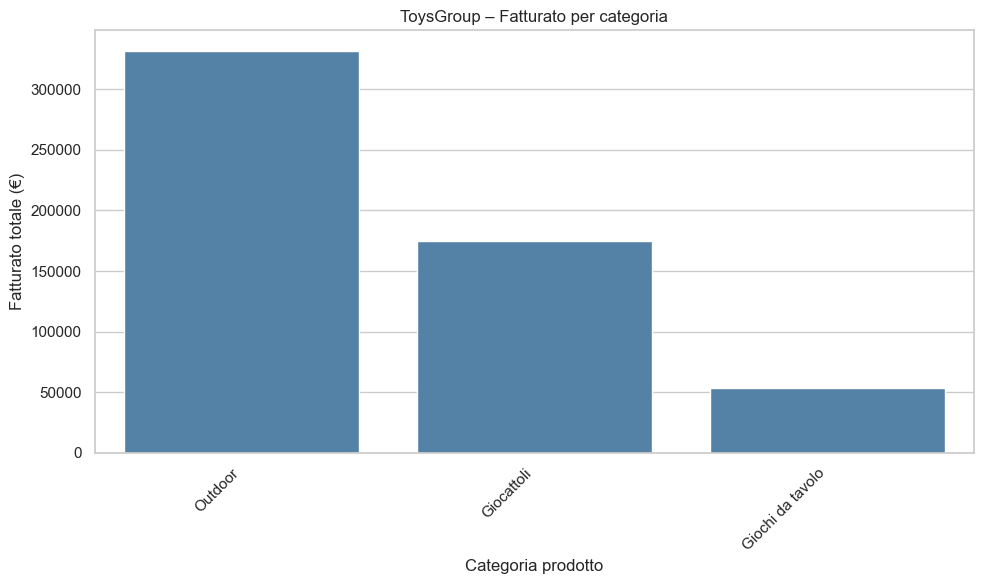

In [195]:

# Prepariamo i dati
dati_categoria = fatturato_categoria.reset_index()

plt.figure(figsize=(10, 6))

sns.barplot(
    data=dati_categoria,
    x="Category",
    y="FatturatoTotale",
    color="steelblue"
)

plt.title("ToysGroup – Fatturato per categoria")
plt.xlabel("Categoria prodotto")
plt.ylabel("Fatturato totale (€)")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()


### 4.2 – Confronto del fatturato per regione

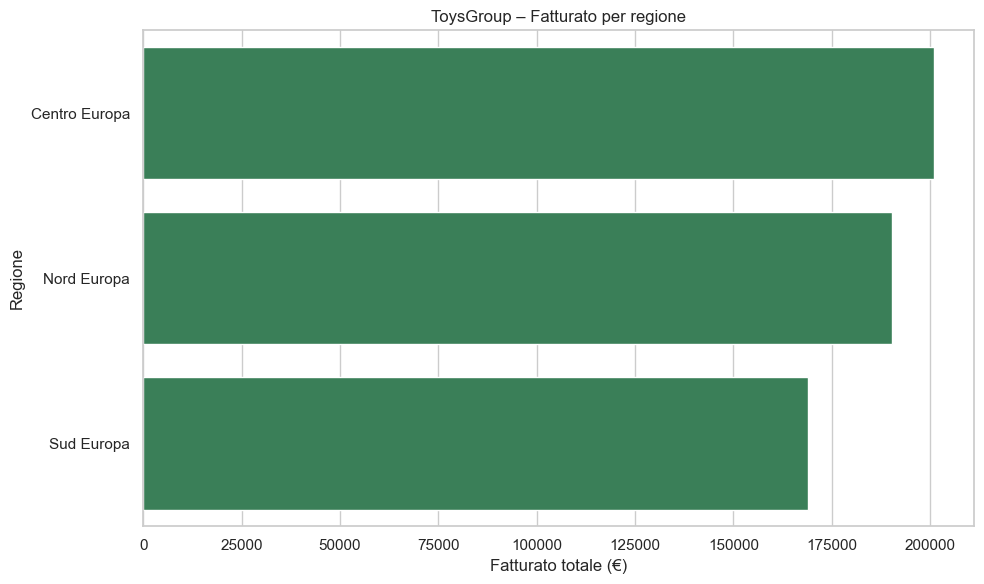

In [196]:

# Prepariamo i dati
dati_regione = fatturato_regione.reset_index()

plt.figure(figsize=(10, 6))

sns.barplot(
    data=dati_regione,
    x="FatturatoTotale",
    y="SalesRegion",
    color="seagreen"
)

plt.title("ToysGroup – Fatturato per regione")
plt.xlabel("Fatturato totale (€)")
plt.ylabel("Regione")

plt.tight_layout()
plt.show()


### 4.3 – Evoluzione temporale del fatturato

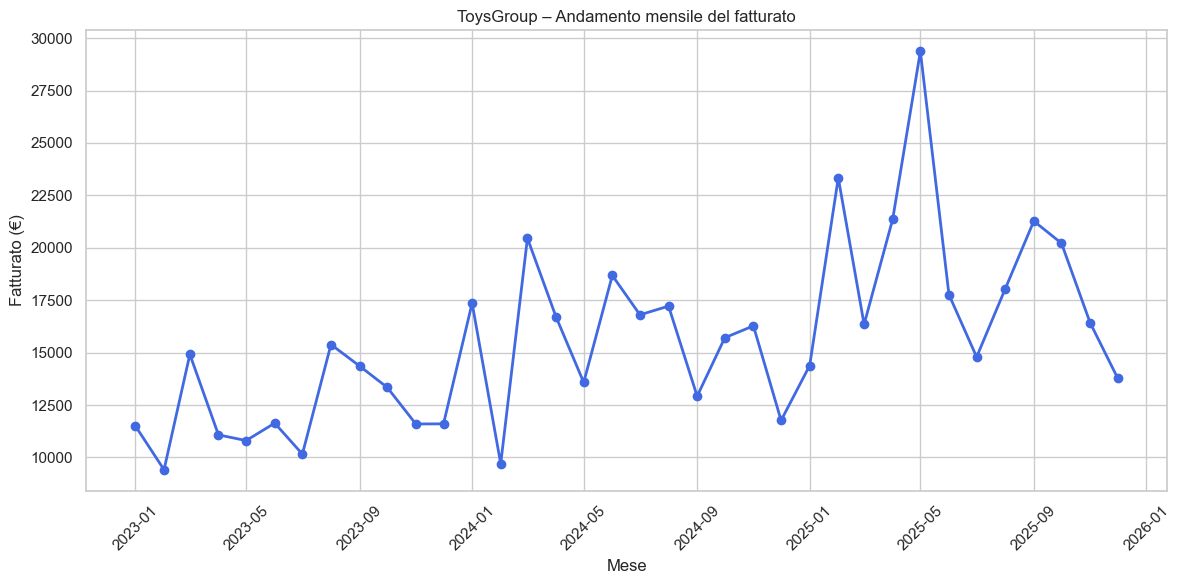

In [197]:

plt.figure(figsize=(12, 6))

plt.plot(
    fatturato_mensile.index,
    fatturato_mensile.values,
    marker="o",
    linewidth=2,
    color="royalblue"
)

plt.title("ToysGroup – Andamento mensile del fatturato")
plt.xlabel("Mese")
plt.ylabel("Fatturato (€)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


### 4.4 – Distribuzione degli importi delle transazioni

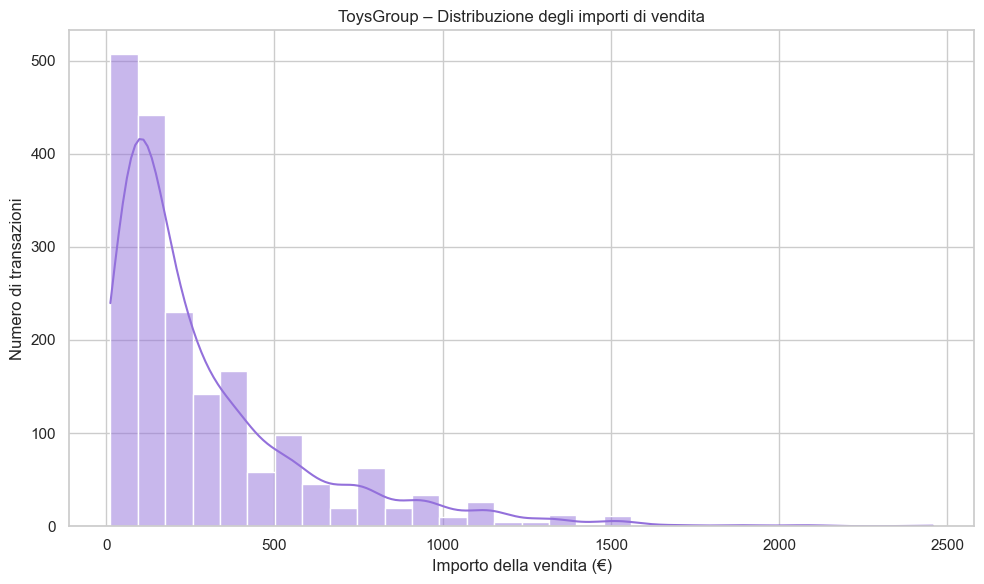

In [198]:

plt.figure(figsize=(10, 6))

sns.histplot(
    data=sales_clean,
    x="SalesAmount",
    bins=30,
    kde=True,
    color="mediumpurple"
)

plt.title("ToysGroup – Distribuzione degli importi di vendita")
plt.xlabel("Importo della vendita (€)")
plt.ylabel("Numero di transazioni")

plt.tight_layout()
plt.show()


### 4.5 – Relazione tra quantità venduta e fatturato

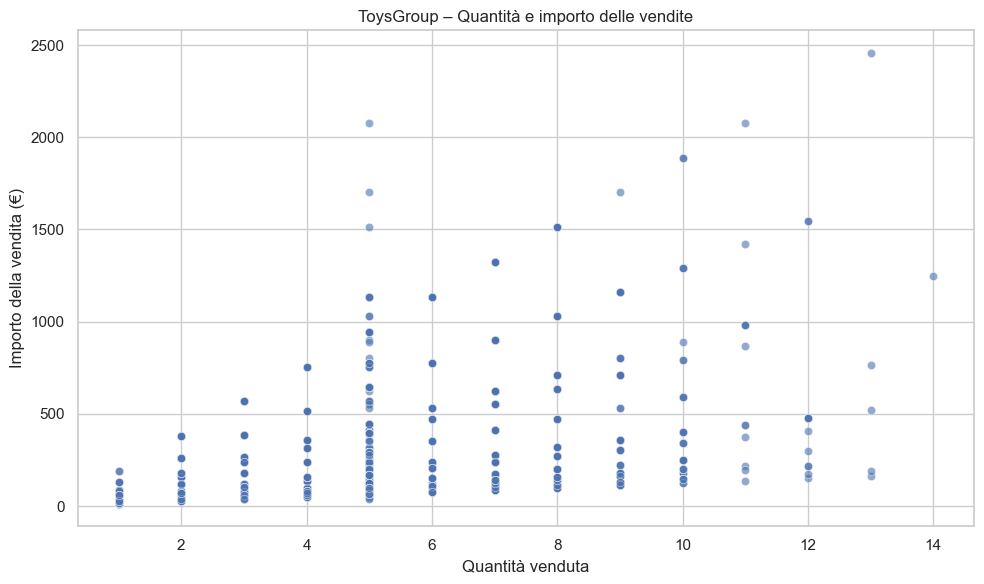

In [199]:

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=sales_clean,
    x="Quantity",
    y="SalesAmount",
    alpha=0.6
)

plt.title("ToysGroup – Quantità e importo delle vendite")
plt.xlabel("Quantità venduta")
plt.ylabel("Importo della vendita (€)")

plt.tight_layout()
plt.show()


### Task 4 – Interpretazione dei grafici

**Grafico 1 – Fatturato per categoria**

Il grafico a barre consente di confrontare il fatturato delle diverse categorie di prodotto e identificare quelle che contribuiscono maggiormente alle vendite complessive.

**Grafico 2 – Fatturato per regione**

Il confronto geografico permette di individuare le differenze di fatturato tra le regioni e valutare la distribuzione delle vendite sul territorio.

**Grafico 3 – Andamento mensile**

Il grafico a linee rappresenta l'evoluzione del fatturato nel tempo, evidenziando eventuali aumenti, diminuzioni e oscillazioni mensili.

**Grafico 4 – Distribuzione degli importi**

L'istogramma permette di osservare la concentrazione degli importi di vendita, la forma della distribuzione e la possibile presenza di valori estremi.

**Grafico 5 – Quantità e fatturato**

Il diagramma a dispersione consente di esplorare l'eventuale relazione tra la quantità venduta e l'importo delle transazioni. La presenza di una tendenza visiva non dimostra necessariamente un rapporto causale.

**Conclusione:** le visualizzazioni aiutano a interpretare i risultati numerici e a individuare aspetti che meritano ulteriori approfondimenti statistici.

## Task 5 – Regressione lineare

### 5.1 – Preparazione dei dati

**Obiettivo:** costruire un modello di regressione lineare per stimare l'importo delle vendite (`SalesAmount`) a partire dalla quantità venduta (`Quantity`).

La variabile indipendente (X) è `Quantity`, mentre la variabile dipendente (y) è `SalesAmount`.

Il dataset viene suddiviso in un insieme di addestramento (80%) e uno di test (20%) per valutare le prestazioni del modello su osservazioni non utilizzate durante l'addestramento.

In [200]:

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Selezione delle variabili
dati_regressione = sales_clean[
    ["Quantity", "SalesAmount"]
].dropna().copy()

X = dati_regressione[["Quantity"]]
y = dati_regressione["SalesAmount"]

# Suddivisione train/test
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Osservazioni train:", len(X_train))
print("Osservazioni test:", len(X_test))


Osservazioni train: 1520
Osservazioni test: 380


### 5.2 – Addestramento del modello

In [201]:

# Creazione del modello
modello_lineare = LinearRegression()

# Addestramento
modello_lineare.fit(X_train, y_train)

# Previsioni sul test set
y_pred = modello_lineare.predict(X_test)

print("Intercetta:", round(modello_lineare.intercept_, 2))
print("Coefficiente Quantity:", round(modello_lineare.coef_[0], 2))

print(
    "Equazione: SalesAmount =",
    round(modello_lineare.intercept_, 2),
    "+",
    round(modello_lineare.coef_[0], 2),
    "* Quantity"
)


Intercetta: 18.76
Coefficiente Quantity: 56.28
Equazione: SalesAmount = 18.76 + 56.28 * Quantity


### 5.3 – Valutazione con MAE, RMSE e R²

In [202]:

# Calcolo delle metriche
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("R²:", round(r2, 4))


MAE: 201.34
RMSE: 268.45
R²: 0.1285


### 5.4 – Confronto tra valori reali e previsti

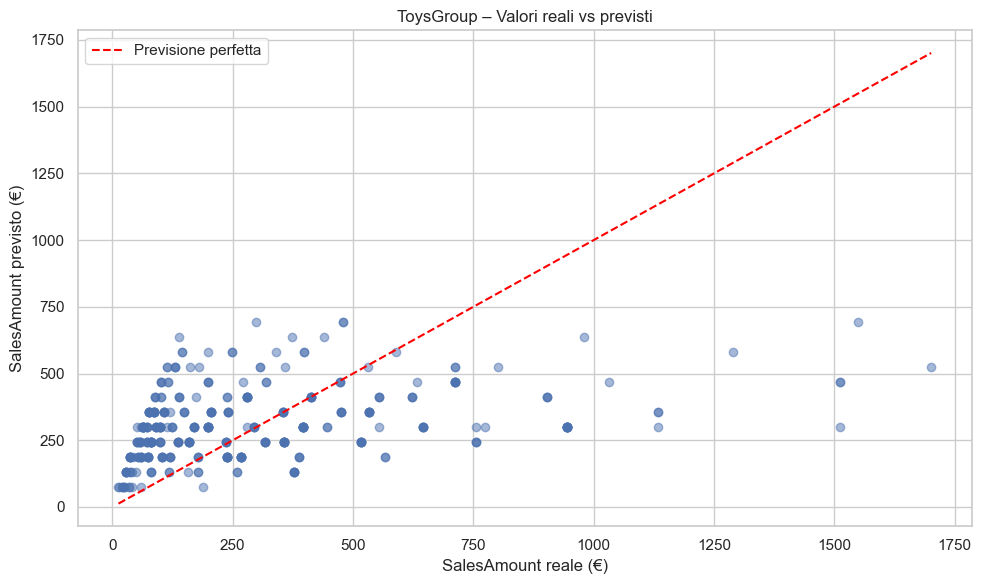

In [203]:

plt.figure(figsize=(10, 6))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.5
)

# Linea ideale: previsione uguale al valore reale
min_val = min(y_test.min(), y_pred.min())
max_val = max(y_test.max(), y_pred.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    linestyle="--",
    color="red",
    label="Previsione perfetta"
)

plt.title("ToysGroup – Valori reali vs previsti")
plt.xlabel("SalesAmount reale (€)")
plt.ylabel("SalesAmount previsto (€)")
plt.legend()

plt.tight_layout()
plt.show()


### 5.5 – Visualizzazione della regressione lineare

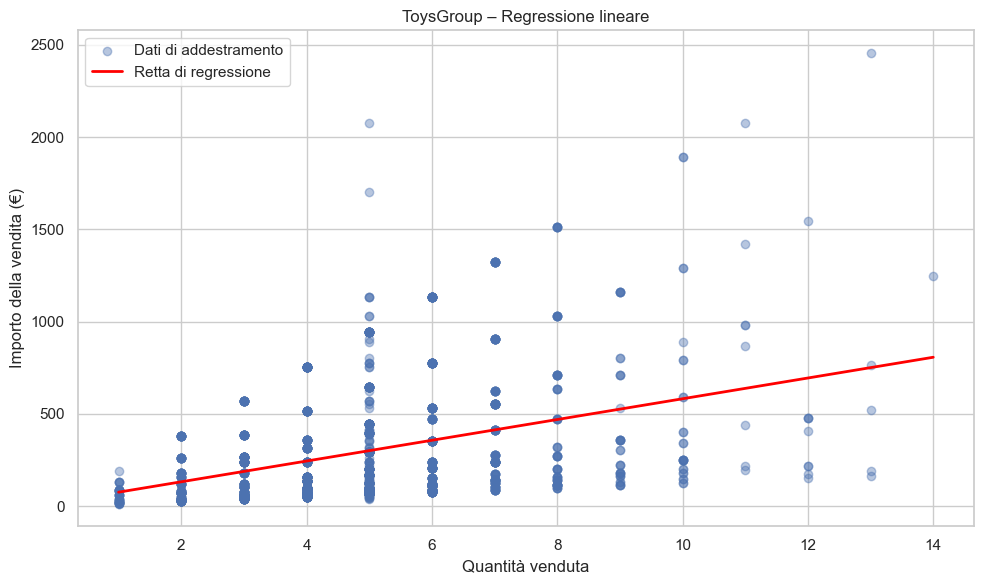

In [204]:

# Ordiniamo i valori di Quantity per disegnare la retta
X_ordinato = X.sort_values("Quantity")

# Previsioni lungo la retta
y_retta = modello_lineare.predict(X_ordinato)

plt.figure(figsize=(10, 6))

plt.scatter(
    X_train["Quantity"],
    y_train,
    alpha=0.4,
    label="Dati di addestramento"
)

plt.plot(
    X_ordinato["Quantity"],
    y_retta,
    color="red",
    linewidth=2,
    label="Retta di regressione"
)

plt.title("ToysGroup – Regressione lineare")
plt.xlabel("Quantità venduta")
plt.ylabel("Importo della vendita (€)")
plt.legend()

plt.tight_layout()
plt.show()


### Risultati ottenuti

- **MAE:** 201,34
- **RMSE:** 268,45
- **R²:** 0,1285

### Considerazioni

Il modello di regressione lineare ha ottenuto un MAE pari a 201,34 e un RMSE pari a 268,45, evidenziando una differenza significativa tra gli importi di vendita reali e quelli previsti.

Il coefficiente R² è pari a 0,1285: il modello riesce quindi a spiegare circa il 12,85% della variabilità di `SalesAmount` nel test set.

Il risultato indica una capacità predittiva limitata, poiché la quantità venduta non è l'unico fattore che determina l'importo di una transazione.

Per migliorare le prestazioni si potrebbero considerare ulteriori variabili, come la categoria del prodotto e il prezzo unitario, purché disponibili al momento della previsione.

**Conclusione:** la regressione lineare costituisce un primo modello di riferimento, ma i risultati suggeriscono la necessità di utilizzare ulteriori caratteristiche per ottenere previsioni più accurate.

## Task 6a – Regressione logistica e classificazione del churn

### 6a.1 – Esplorazione dei dati

**Obiettivo:** costruire un modello di classificazione binaria per analizzare il churn dei rivenditori ToysGroup.

Prima di addestrare il modello, vengono esaminate le variabili disponibili e verificata la presenza di una variabile target che identifichi i rivenditori che hanno abbandonato.

In [205]:

# Esplorazione del dataset dei rivenditori
print("Dimensioni del dataset:", resellers.shape)

print("\nNomi delle colonne:")
print(resellers.columns.tolist())

print("\nTipi di dato e valori mancanti:")
resellers.info()

print("\nPrime 5 righe:")
display(resellers.head())

print("\nValori mancanti:")
display(resellers.isna().sum())


Dimensioni del dataset: (300, 7)

Nomi delle colonne:
['ResellerID', 'RegionID', 'Ordini12m', 'GiorniUltimoOrdine', 'ScontoMedio', 'Reclami', 'Churn']

Tipi di dato e valori mancanti:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   ResellerID          300 non-null    int64  
 1   RegionID            300 non-null    int64  
 2   Ordini12m           300 non-null    int64  
 3   GiorniUltimoOrdine  300 non-null    int64  
 4   ScontoMedio         300 non-null    float64
 5   Reclami             300 non-null    int64  
 6   Churn               300 non-null    int64  
dtypes: float64(1), int64(6)
memory usage: 16.5 KB

Prime 5 righe:


,ResellerID,RegionID,Ordini12m,GiorniUltimoOrdine,ScontoMedio,Reclami,Churn
0,1,1,14,65,0.131,1,0
1,2,7,9,149,0.117,1,0
2,3,6,21,1,0.065,2,0
3,4,4,18,162,0.011,1,1
4,5,4,22,98,0.120,0,0



Valori mancanti:


ResellerID            0
RegionID              0
Ordini12m             0
GiorniUltimoOrdine    0
ScontoMedio           0
Reclami               0
Churn                 0
dtype: int64

### 6a.2 – Identificazione della variabile target

In [206]:

# Cerchiamo possibili colonne relative al churn
colonne_target = [
    col for col in resellers.columns
    if any(parola in col.lower() for parola in [
        "churn", "inactive", "active", "status",
        "abandon", "retention"
    ])
]

print("Possibili colonne target:")
print(colonne_target)

# Se presenti, osserviamo i valori distinti
for col in colonne_target:
    print(f"\nValori della colonna {col}:")
    print(resellers[col].value_counts(dropna=False))


Possibili colonne target:
['Churn']

Valori della colonna Churn:
Churn
0    229
1     71
Name: count, dtype: int64


### 6a.3 – Impostazione del modello

La regressione logistica è un algoritmo di apprendimento supervisionato utilizzato per problemi di classificazione.

Nel caso del churn, l'obiettivo è stimare la probabilità che un rivenditore appartenga alla classe di abbandono.

Una volta identificata la variabile target, il modello verrà addestrato attraverso una suddivisione dei dati in training set e test set.

Le prestazioni saranno valutate mediante metriche come accuracy, precision, recall, F1-score e matrice di confusione.

Accuracy: 0.7667

Classification report:
              precision    recall  f1-score   support

           0       0.81      0.91      0.86        46
           1       0.50      0.29      0.36        14

    accuracy                           0.77        60
   macro avg       0.65      0.60      0.61        60
weighted avg       0.74      0.77      0.74        60



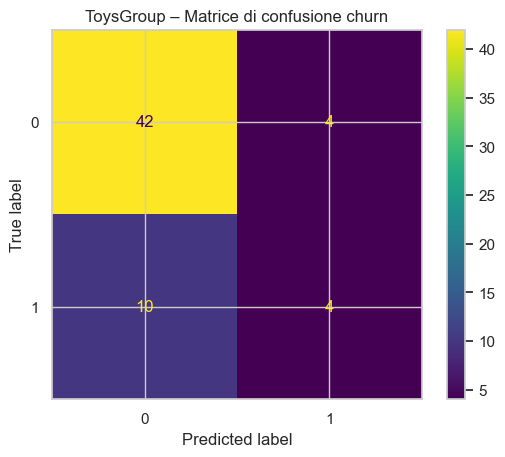

In [207]:

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)

# Cerchiamo una variabile target esplicita
possibili_target = [
    col for col in resellers.columns
    if col.lower() in ["churn", "ischurned", "churned"]
]

if len(possibili_target) != 1:
    print("Serve identificare la colonna target del churn.")
    print("Colonne disponibili:")
    print(resellers.columns.tolist())

else:
    target = possibili_target[0]

    # Accettiamo solo target già codificati 0 e 1
    dati = resellers.dropna(subset=[target]).copy()
    valori = set(dati[target].unique())

    if valori != {0, 1}:
        print("La colonna target deve essere verificata.")
        print("Valori presenti:", valori)

    else:
        # Selezioniamo le variabili numeriche
        X = dati.drop(columns=[target]).select_dtypes(
            include="number"
        )

        # Escludiamo possibili identificativi
        X = X.loc[:, [
            col for col in X.columns
            if not col.lower().endswith("id")
        ]]

        y = dati[target].astype(int)

        if X.empty or y.value_counts().min() < 2:
            print("Dati insufficienti per addestrare il modello.")

        else:
            X_train, X_test, y_train, y_test = train_test_split(
                X, y,
                test_size=0.20,
                random_state=42,
                stratify=y
            )

            modello_churn = make_pipeline(
                SimpleImputer(strategy="median"),
                StandardScaler(),
                LogisticRegression(max_iter=1000)
            )

            modello_churn.fit(X_train, y_train)
            y_pred_churn = modello_churn.predict(X_test)

            print("Accuracy:",
                  round(accuracy_score(y_test, y_pred_churn), 4))

            print("\nClassification report:")
            print(classification_report(
                y_test, y_pred_churn, zero_division=0
            ))

            ConfusionMatrixDisplay.from_predictions(
                y_test, y_pred_churn
            )
            plt.title("ToysGroup – Matrice di confusione churn")
            plt.show()


### 6a.4 – Interpretazione della regressione logistica

La regressione logistica è un algoritmo di classificazione supervisionata che permette di stimare la probabilità di appartenenza a una classe.

Per valutare il modello vengono considerate le seguenti metriche:

- **Accuracy:** percentuale delle classificazioni corrette.
- **Precision:** proporzione di rivenditori realmente abbandonati tra quelli classificati come churn.
- **Recall:** proporzione di rivenditori abbandonati che il modello riesce a identificare.
- **F1-score:** media armonica di precision e recall.
- **Matrice di confusione:** rappresenta le classificazioni corrette e gli errori del modello.

I risultati numerici e la loro interpretazione saranno riportati dopo aver verificato la disponibilità e il significato della variabile target.

## Task 6b – Clustering con KMeans

### 6b.1 – Preparazione dei dati

**Obiettivo:** segmentare i rivenditori ToysGroup attraverso l'algoritmo KMeans, individuando gruppi con comportamenti di acquisto simili.

L'analisi utilizza informazioni aggregate sulle vendite, come il fatturato totale, la quantità acquistata e il numero di transazioni per rivenditore.

In [208]:

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

# Verifichiamo le colonne disponibili
print("Colonne vendite:")
print(sales_clean.columns.tolist())

print("\nColonne rivenditori:")
print(resellers.columns.tolist())

# Individuiamo la chiave del rivenditore
chiavi = [
    col for col in ["ResellerID", "ResellerId"]
    if col in sales_clean.columns
]

if not chiavi:
    raise ValueError(
        "Non trovo la colonna identificativa del rivenditore. "
        "Controlla l'elenco delle colonne visualizzato."
    )

chiave = chiavi[0]

# Aggregazione delle vendite per rivenditore
reseller_features = (
    sales_clean
    .dropna(subset=[chiave])
    .groupby(chiave)
    .agg(
        FatturatoTotale=("SalesAmount", "sum"),
        QuantitaTotale=("Quantity", "sum"),
        NumeroTransazioni=("SalesAmount", "size")
    )
    .reset_index()
)

display(reseller_features.head())
print("Rivenditori analizzati:", len(reseller_features))


Colonne vendite:
['SalesID', 'ProductID', 'RegionID', 'ResellerID', 'SalesDate', 'Quantity', 'SalesAmount']

Colonne rivenditori:
['ResellerID', 'RegionID', 'Ordini12m', 'GiorniUltimoOrdine', 'ScontoMedio', 'Reclami', 'Churn']


,ResellerID,FatturatoTotale,QuantitaTotale,NumeroTransazioni
0,1,2018.1,22.0,5
1,2,2468.6,30.0,6
2,3,2463.6,33.0,7
3,4,1183.3,30.0,7
4,5,907.6,25.0,6


Rivenditori analizzati: 296


### 6b.2 – Standardizzazione delle variabili

In [209]:

# Selezioniamo le caratteristiche numeriche
features = [
    "FatturatoTotale",
    "QuantitaTotale",
    "NumeroTransazioni"
]

X_cluster = reseller_features[features].copy()

# Standardizzazione
scaler_cluster = StandardScaler()
X_scaled = scaler_cluster.fit_transform(X_cluster)

print("Dimensioni dati standardizzati:", X_scaled.shape)
print("Prime 5 righe:")
print(X_scaled[:5])


Dimensioni dati standardizzati: (296, 3)
Prime 5 righe:
[[ 0.10851442 -0.61721855 -0.46893695]
 [ 0.49664119 -0.11821769 -0.13844805]
 [ 0.49233346  0.06890764  0.19204085]
 [-0.61070473 -0.11821769  0.19204085]
 [-0.84823315 -0.43009322 -0.13844805]]


### 6b.3 – Scelta del numero di cluster con il metodo del gomito

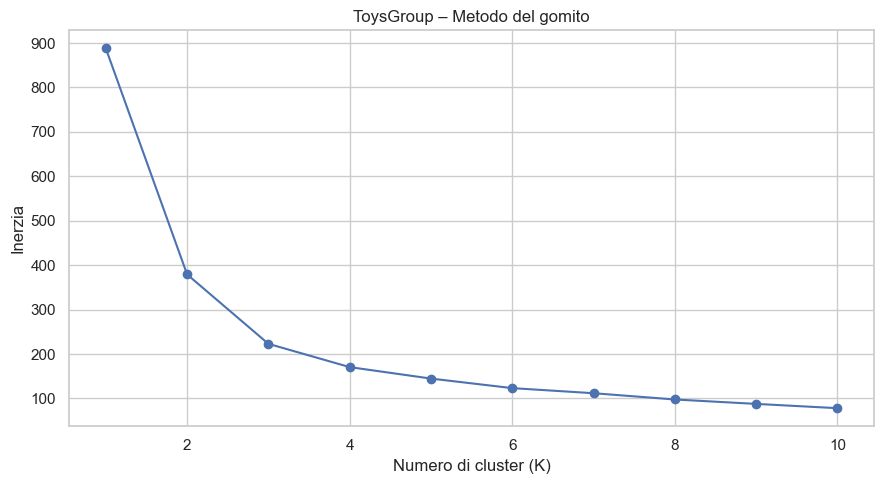

In [210]:

# Calcoliamo l'inerzia per diversi valori di K
inerzie = []

numero_rivenditori = len(X_scaled)
max_k = min(10, numero_rivenditori)

if max_k < 2:
    raise ValueError("Servono almeno 2 rivenditori.")

valori_k = range(1, max_k + 1)

for k in valori_k:
    modello = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    modello.fit(X_scaled)
    inerzie.append(modello.inertia_)

plt.figure(figsize=(9, 5))
plt.plot(list(valori_k), inerzie, marker="o")

plt.title("ToysGroup – Metodo del gomito")
plt.xlabel("Numero di cluster (K)")
plt.ylabel("Inerzia")

plt.tight_layout()
plt.show()


### 6b.4 – Valutazione del clustering con silhouette score

In [211]:

# Valutiamo diversi numeri di cluster
risultati_silhouette = {}

for k in range(2, min(10, numero_rivenditori - 1) + 1):
    modello = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    etichette = modello.fit_predict(X_scaled)

    if len(set(etichette)) > 1:
        score = silhouette_score(X_scaled, etichette)
        risultati_silhouette[k] = score

if not risultati_silhouette:
    raise ValueError(
        "Non ci sono abbastanza rivenditori per calcolare "
        "il silhouette score."
    )

print("Silhouette score per numero di cluster:")

for k, score in risultati_silhouette.items():
    print(f"K={k}: {score:.4f}")

k_ottimale = max(
    risultati_silhouette,
    key=risultati_silhouette.get
)

print("\nK migliore secondo silhouette:", k_ottimale)


Silhouette score per numero di cluster:
K=2: 0.4717
K=3: 0.4524
K=4: 0.3661
K=5: 0.3345
K=6: 0.3377
K=7: 0.3053
K=8: 0.3168
K=9: 0.3181
K=10: 0.3294

K migliore secondo silhouette: 2


### Risultati del clustering KMeans

Il numero di cluster è stato valutato confrontando diverse configurazioni, da K = 2 a K = 10, attraverso il silhouette score.

La configurazione migliore è risultata **K = 2**, con un silhouette score pari a **0,4717**.

Questo risultato indica una separazione moderata tra i gruppi individuati. Le configurazioni con un numero maggiore di cluster hanno ottenuto valori inferiori.

La scelta di due cluster rappresenta quindi la soluzione migliore tra quelle analizzate secondo il criterio del silhouette score.

Per interpretare le caratteristiche commerciali dei due segmenti è necessario confrontare il fatturato medio, la quantità media acquistata e il numero medio di transazioni dei rivenditori appartenenti a ciascun gruppo.

### 6b.5 – Addestramento finale di KMeans

In [212]:

# Creiamo il modello con il K selezionato
kmeans_finale = KMeans(
    n_clusters=k_ottimale,
    random_state=42,
    n_init=10
)

# Assegniamo ogni rivenditore a un cluster
reseller_features["Cluster"] = (
    kmeans_finale.fit_predict(X_scaled)
)

print("Numero rivenditori per cluster:")
display(
    reseller_features["Cluster"]
    .value_counts()
    .sort_index()
)

print("\nCaratteristiche medie dei cluster:")
profilo_cluster = (
    reseller_features
    .groupby("Cluster")[features]
    .mean()
    .round(2)
)

display(profilo_cluster)


Numero rivenditori per cluster:


Cluster
0    126
1    170
Name: count, dtype: int64


Caratteristiche medie dei cluster:


,FatturatoTotale,QuantitaTotale,NumeroTransazioni
Cluster,,,
0,2858.85,46.58,9.10
1,1175.65,21.01,4.43


### 6b.6 – Visualizzazione dei segmenti

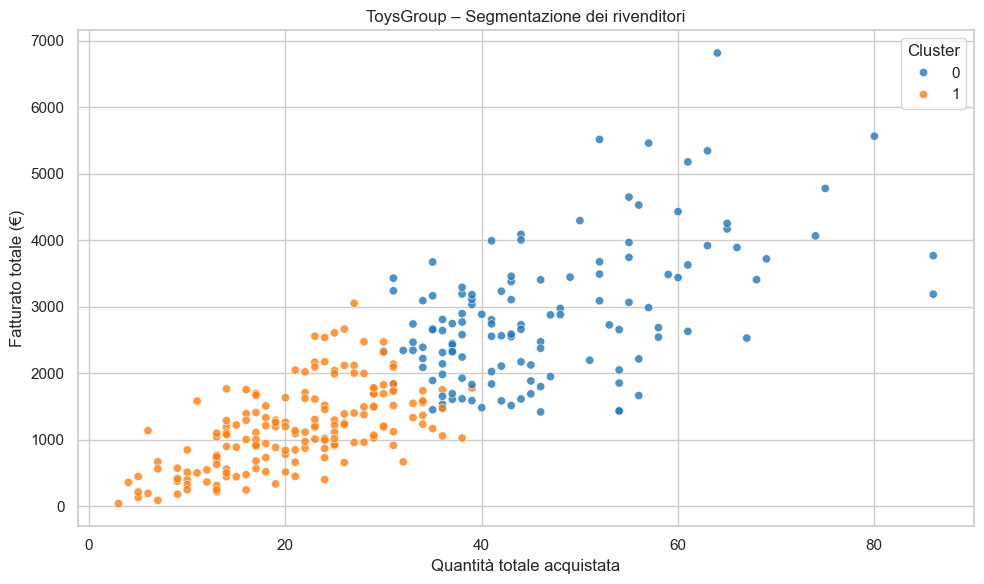

In [213]:

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=reseller_features,
    x="QuantitaTotale",
    y="FatturatoTotale",
    hue="Cluster",
    palette="tab10",
    alpha=0.8
)

plt.title("ToysGroup – Segmentazione dei rivenditori")
plt.xlabel("Quantità totale acquistata")
plt.ylabel("Fatturato totale (€)")
plt.legend(title="Cluster")

plt.tight_layout()
plt.show()


### Risultati

**Numero di cluster selezionato:** 2

**Silhouette score:** 0,4717

L'algoritmo KMeans ha individuato due gruppi di rivenditori, selezionati attraverso il confronto dei silhouette score per valori di K compresi tra 2 e 10.

Il valore di 0,4717 indica una separazione moderata tra i cluster.

### Interpretazione dei segmenti

**Cluster 0 – Rivenditori ad alta attività commerciale**

Comprende 126 rivenditori, caratterizzati mediamente da:

- Fatturato totale: 2.858,85 €
- Quantità acquistata: 46,58 unità
- Numero di transazioni: 9,10

**Cluster 1 – Rivenditori a minore attività commerciale**

Comprende 170 rivenditori, caratterizzati mediamente da:

- Fatturato totale: 1.175,65 €
- Quantità acquistata: 21,01 unità
- Numero di transazioni: 4,43

### Considerazioni

Il clustering evidenzia due segmenti commerciali distinti: uno con livelli medi di fatturato, quantità e transazioni più elevati, e uno caratterizzato da un'attività inferiore.

Questa segmentazione può supportare strategie commerciali differenziate, ad esempio attraverso iniziative di fidelizzazione dei rivenditori più attivi e attività di sviluppo commerciale rivolte ai rivenditori con volumi inferiori.

La segmentazione non dimostra automaticamente un rischio di abbandono: per valutare il churn è necessario utilizzare il modello di classificazione specifico del Task 6a.

**Conclusione:** KMeans ha permesso di identificare due gruppi di rivenditori con caratteristiche commerciali differenti, fornendo informazioni utili per ulteriori analisi e decisioni aziendali.

## Task 7 – Debugging e verifica finale

### 7.1 – Controllo della qualità dei dati

**Obiettivo:** verificare la correttezza dei dataset utilizzati, la presenza di eventuali valori mancanti e la coerenza dei risultati ottenuti durante l'analisi.

In [214]:

# Verifica dei dataset
print("=== CONTROLLO DATASET ===")

dataset = {
    "Products": products,
    "Regions": regions,
    "Sales originali": sales,
    "Sales pulite": sales_clean,
    "Resellers": resellers
}

for nome, df in dataset.items():
    print(f"\n{nome}")
    print("Righe:", df.shape[0])
    print("Colonne:", df.shape[1])
    print("Valori mancanti:", df.isna().sum().sum())
    print("Duplicati completi:", df.duplicated().sum())

print("\n=== CONTROLLO PULIZIA ===")

assert sales_clean["Quantity"].isna().sum() == 0
assert sales_clean["SalesAmount"].isna().sum() == 0
assert len(sales_clean) <= len(sales)

print("Controlli sulla pulizia superati!")


=== CONTROLLO DATASET ===

Products
Righe: 12
Colonne: 4
Valori mancanti: 0
Duplicati completi: 0

Regions
Righe: 9
Colonne: 3
Valori mancanti: 0
Duplicati completi: 0

Sales originali
Righe: 2000
Colonne: 7
Valori mancanti: 200
Duplicati completi: 0

Sales pulite
Righe: 1900
Colonne: 7
Valori mancanti: 0
Duplicati completi: 0

Resellers
Righe: 300
Colonne: 7
Valori mancanti: 0
Duplicati completi: 0

=== CONTROLLO PULIZIA ===
Controlli sulla pulizia superati!


### 7.2 – Controllo di coerenza delle aggregazioni

In [215]:

import numpy as np

# Verifica che le aggregazioni conservino il fatturato
totale_vendite = sales_clean["SalesAmount"].sum()
totale_merge = sales_merged["SalesAmount"].sum()

print("Fatturato originale pulito:", round(totale_vendite, 2))
print("Fatturato dopo il merge:", round(totale_merge, 2))

assert np.isclose(totale_vendite, totale_merge), (
    "Il fatturato è cambiato dopo il merge!"
)

# Verifica del numero di righe
assert len(sales_clean) == len(sales_merged), (
    "Il numero delle transazioni è cambiato!"
)

print("Controlli di coerenza superati!")


Fatturato originale pulito: 560075.5
Fatturato dopo il merge: 560075.5
Controlli di coerenza superati!


## Conclusioni del progetto ToysGroup

Il progetto ha permesso di applicare tecniche di analisi dei dati e Machine Learning ai dataset commerciali ToysGroup, utilizzando Python, Pandas, NumPy, Matplotlib, Seaborn e Scikit-learn.

**Preparazione e qualità dei dati:** sono stati analizzati quattro dataset in diversi formati. Il dataset delle vendite conteneva inizialmente 2.000 transazioni e 200 valori mancanti. Dopo il trattamento, sono rimaste 1.900 transazioni senza valori mancanti.

**Analisi delle vendite:** le operazioni di aggregazione e integrazione dei dati hanno consentito di analizzare il fatturato per categoria, regione e periodo. Il fatturato complessivo delle vendite pulite è pari a **560.075,50 €** e risulta invariato dopo i merge.

**Visualizzazione:** i grafici hanno consentito di esplorare la distribuzione delle vendite e le relazioni tra le variabili.

**Regressione lineare:** il modello basato sulla quantità venduta ha ottenuto un MAE di 201,34, un RMSE di 268,45 e un R² di 0,1285. Il risultato evidenzia una capacità predittiva limitata utilizzando esclusivamente la quantità come variabile indipendente.

**Classificazione del churn:** il modello di regressione logistica ha ottenuto un'accuracy del 76,67%. Tuttavia, la recall della classe churn è risultata pari al 29%, evidenziando difficoltà nell'identificare i rivenditori che abbandonano.

**Clustering KMeans:** sono stati individuati due gruppi di rivenditori, con un silhouette score di 0,4717. Il primo gruppo comprende 126 rivenditori con maggiore attività commerciale, mentre il secondo ne comprende 170 con volumi medi inferiori.

**Conclusione generale:** l'analisi ha evidenziato come le tecniche di Data Analysis e Machine Learning possano supportare l'interpretazione dei dati commerciali. I risultati mostrano anche l'importanza di valutare criticamente le prestazioni dei modelli, riconoscendone i limiti e individuando possibili miglioramenti.